In [1]:
#!pip install biopython pandas matplotlib seaborn pyarrow openpyxl umap-learn plotly

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import scipy as sp
import pandas as pd
import networkx as nx
import random
import matplotlib.pyplot as plt
# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)
from IPython.core.display import HTML
HTML('<style>.container { width:95% !important; }</style><style>.output_png {display: table-cell;text-align: center;vertical-align: middle;}</style>')

In [3]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

In [ ]:

from amr.predictive import (
    baseline_global_average,
    baseline_persistence,
    build_amr_with_embeddings,
    build_data_and_target,
    build_taxonomy_onehot,
    leave_one_pathogen_out_with_embeddings,
    random_forest_experiment_with_embeddings,
)


---

In [5]:
antibiotics_df = pd.read_excel("antibiotic_list.xlsx")
antibiotics_list = antibiotics_df['Antibiotic'].values
print(f'#antibiotics: {len(antibiotics_list)}')

data_df = pd.read_parquet("data.parquet")
pathogens_list = data_df[data_df['n_causation']>=3]['CanonicalSpecies'].values
data_df, taxonomy_onehot = build_taxonomy_onehot(data_df)
print(f'#pathogens: {len(pathogens_list)}')

#antibiotics: 257
#pathogens: 773


In [6]:
data_df

,Genus,CanonicalSpecies,n_causation,n_articles,n_sampled,pathogenic_index,embedding,anonymised_embedding,onehot_embedding,domain,kingdom,phylum,class,order,family,taxonomy_embeddings
0,Abiotrophia,Abiotrophia defectiva,6,6,6,0.160939,"[0.018194107338786125, -0.004734894765230517, ...","[0.014040807844139636, -0.028420374651129048, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.166...",Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Aerococcaceae,"[0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, ..."
1,Acetobacter,Acetobacter indonesiensis,1,3,3,0.000000,"[-0.021512236446142197, -0.03992129862308502, ...","[-0.0028289835900068283, -0.04833690822124481,...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
2,Acetobacter,Acetobacter tropicalis,1,2,2,0.000000,"[-0.0070418259128928185, -0.005829853471368551...","[0.005147432442754507, -0.013049994595348835, ...","[0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
3,Achromobacter,Achromobacter animicus,1,2,2,0.000000,"[0.011074555106461048, 0.013332720845937729, 0...","[0.012643104419112206, -0.01178667601197958, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
4,Achromobacter,Achromobacter denitrificans,75,36,36,0.387804,"[0.014773702074987037, -0.004635852294159122, ...","[0.011467029051855206, -0.012983008560258896, ...","[0.04, 0.013333333333333334, 0.066666666666666...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1274,Yersinia,Yersinia enterocolitica,85,3419,200,0.654031,"[-0.009990866917788105, 0.009774883079979405, ...","[0.0024005417033656747, -0.009907858140479005,...","[0.0, 0.0, 0.0, 0.03529411764705882, 0.0, 0.0,...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
1275,Yersinia,Yersinia frederiksenii,1,21,21,0.000000,"[-0.00901515781879425, 0.02502085641026497, 0....","[0.01804814115166664, 0.005011445842683315, 0....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
1276,Yersinia,Yersinia pestis,124,2184,200,0.647694,"[-0.006688895473886195, 0.014983039929487154, ...","[0.011833864605177364, -0.0048193380043226024,...","[0.0, 0.0, 0.0, 0.016129032258064516, 0.0, 0.0...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
1277,Yersinia,Yersinia pseudotuberculosis,88,1234,200,0.565611,"[-0.01641193700528344, 0.008593090970448842, 0...","[0.004612311640316461, -0.005791128928070644, ...","[0.011363636363636364, 0.0, 0.0113636363636363...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."


In [7]:
amr_df = pd.read_parquet("pmids_results.parquet")
amr_df

,pathogen,antibiotic,start_date,end_date,pmids,count
0,Staphylococcus argenteus,Spectinomycin,1975/01/01,1984/12/31,[],0
1,Staphylococcus argenteus,Spectinomycin,1985/01/01,1994/12/31,[],0
2,Staphylococcus argenteus,Spectinomycin,1995/01/01,2004/12/31,[],0
3,Staphylococcus argenteus,Spectinomycin,2005/01/01,2014/12/31,[],0
4,Staphylococcus argenteus,Spectinomycin,2015/01/01,2024/12/31,[],0
...,...,...,...,...,...,...
50110,Neisseria weaveri,Trimethoprim,1975/01/01,1984/12/31,[],0
50111,Neisseria weaveri,Trimethoprim,1985/01/01,1994/12/31,[],0
50112,Neisseria weaveri,Trimethoprim,1995/01/01,2004/12/31,[8758472],1
50113,Neisseria weaveri,Trimethoprim,2005/01/01,2014/12/31,[],0


---

In [11]:
X, Y, feature_df, target_df = build_data_and_target(amr_df)

r2_persist, rmse_persist = baseline_persistence(feature_df, target_df)
print(f"Persistence baseline: R²={r2_persist:.3f}, RMSE={rmse_persist:.3f}")

r2_avg, rmse_avg = baseline_global_average(target_df)
print(f"Global average baseline: R²={r2_avg:.3f}, RMSE={rmse_avg:.3f}")


Persistence baseline: R²=0.579, RMSE=0.291
Global average baseline: R²=0.298, RMSE=0.628


In [12]:
%%time
results, avg_scores = random_forest_experiment_with_embeddings(
    amr_df,
    data_df,
    embedding_cols=None,
    n_repeats=5,
    n_estimators=300,
    max_depth=None
)

Repeat 1/5: R²=0.600, RMSE=0.174
Repeat 2/5: R²=0.372, RMSE=0.363
Repeat 3/5: R²=0.375, RMSE=0.243
Repeat 4/5: R²=0.378, RMSE=0.335
Repeat 5/5: R²=0.188, RMSE=0.386

Average Performance:
  R²   = 0.383 ± 0.130
  RMSE = 0.300 ± 0.080
CPU times: user 23min 29s, sys: 1min 59s, total: 25min 28s
Wall time: 19min 17s


In [15]:
%%time
results_embeddings, avg_scores_embeddings = random_forest_experiment_with_embeddings(
    amr_df,
    data_df,
    embedding_cols=["taxonomy_embeddings", "anonymised_embedding"],
    n_repeats=5,
    n_estimators=300,
    max_depth=None
)

Repeat 1/5: R²=0.273, RMSE=0.217
Repeat 2/5: R²=0.208, RMSE=0.406
Repeat 3/5: R²=0.048, RMSE=0.360
Repeat 4/5: R²=0.232, RMSE=0.408
Repeat 5/5: R²=0.071, RMSE=0.428

Average Performance:
  R²   = 0.166 ± 0.090
  RMSE = 0.364 ± 0.077
CPU times: user 1h 2min 42s, sys: 2min 1s, total: 1h 4min 43s
Wall time: 19min 41s


---

In [9]:
%%time
RUN_EXPERIMENT = False # Set to False to load existing results

if RUN_EXPERIMENT:
    results_df = leave_one_pathogen_out_with_embeddings(
        amr_df,
        data_df,
        embedding_cols=["taxonomy_embeddings", "anonymised_embedding"],
        n_estimators=300
    )
    results_df.to_parquet("results.parquet", index=False)
else:
    results_df = pd.read_parquet("results.parquet")

results_df

CPU times: user 9.28 ms, sys: 4.75 ms, total: 14 ms
Wall time: 9.13 ms


,pathogen,antibiotic,actual_count,predicted_count,difference
0,Neisseria animaloris,Amikacin,0.0,0.659501,0.659501
1,Neisseria animaloris,Amoxicillin,1.0,1.326451,0.326451
2,Neisseria animaloris,Amoxicillin/clavulanic-acid,1.0,0.933271,-0.066729
3,Neisseria animaloris,Ampicillin,0.0,1.275252,1.275252
4,Neisseria animaloris,Ampicillin/sulbactam,0.0,0.596933,0.596933
...,...,...,...,...,...
9823,Staphylococcus xylosus,Tosufloxacin,0.0,0.044018,0.044018
9824,Staphylococcus xylosus,Troleandomycin,0.0,0.000000,0.000000
9825,Staphylococcus xylosus,Trovafloxacin,0.0,0.004632,0.004632
9826,Staphylococcus xylosus,Vancomycin_IV,0.0,0.010787,0.010787


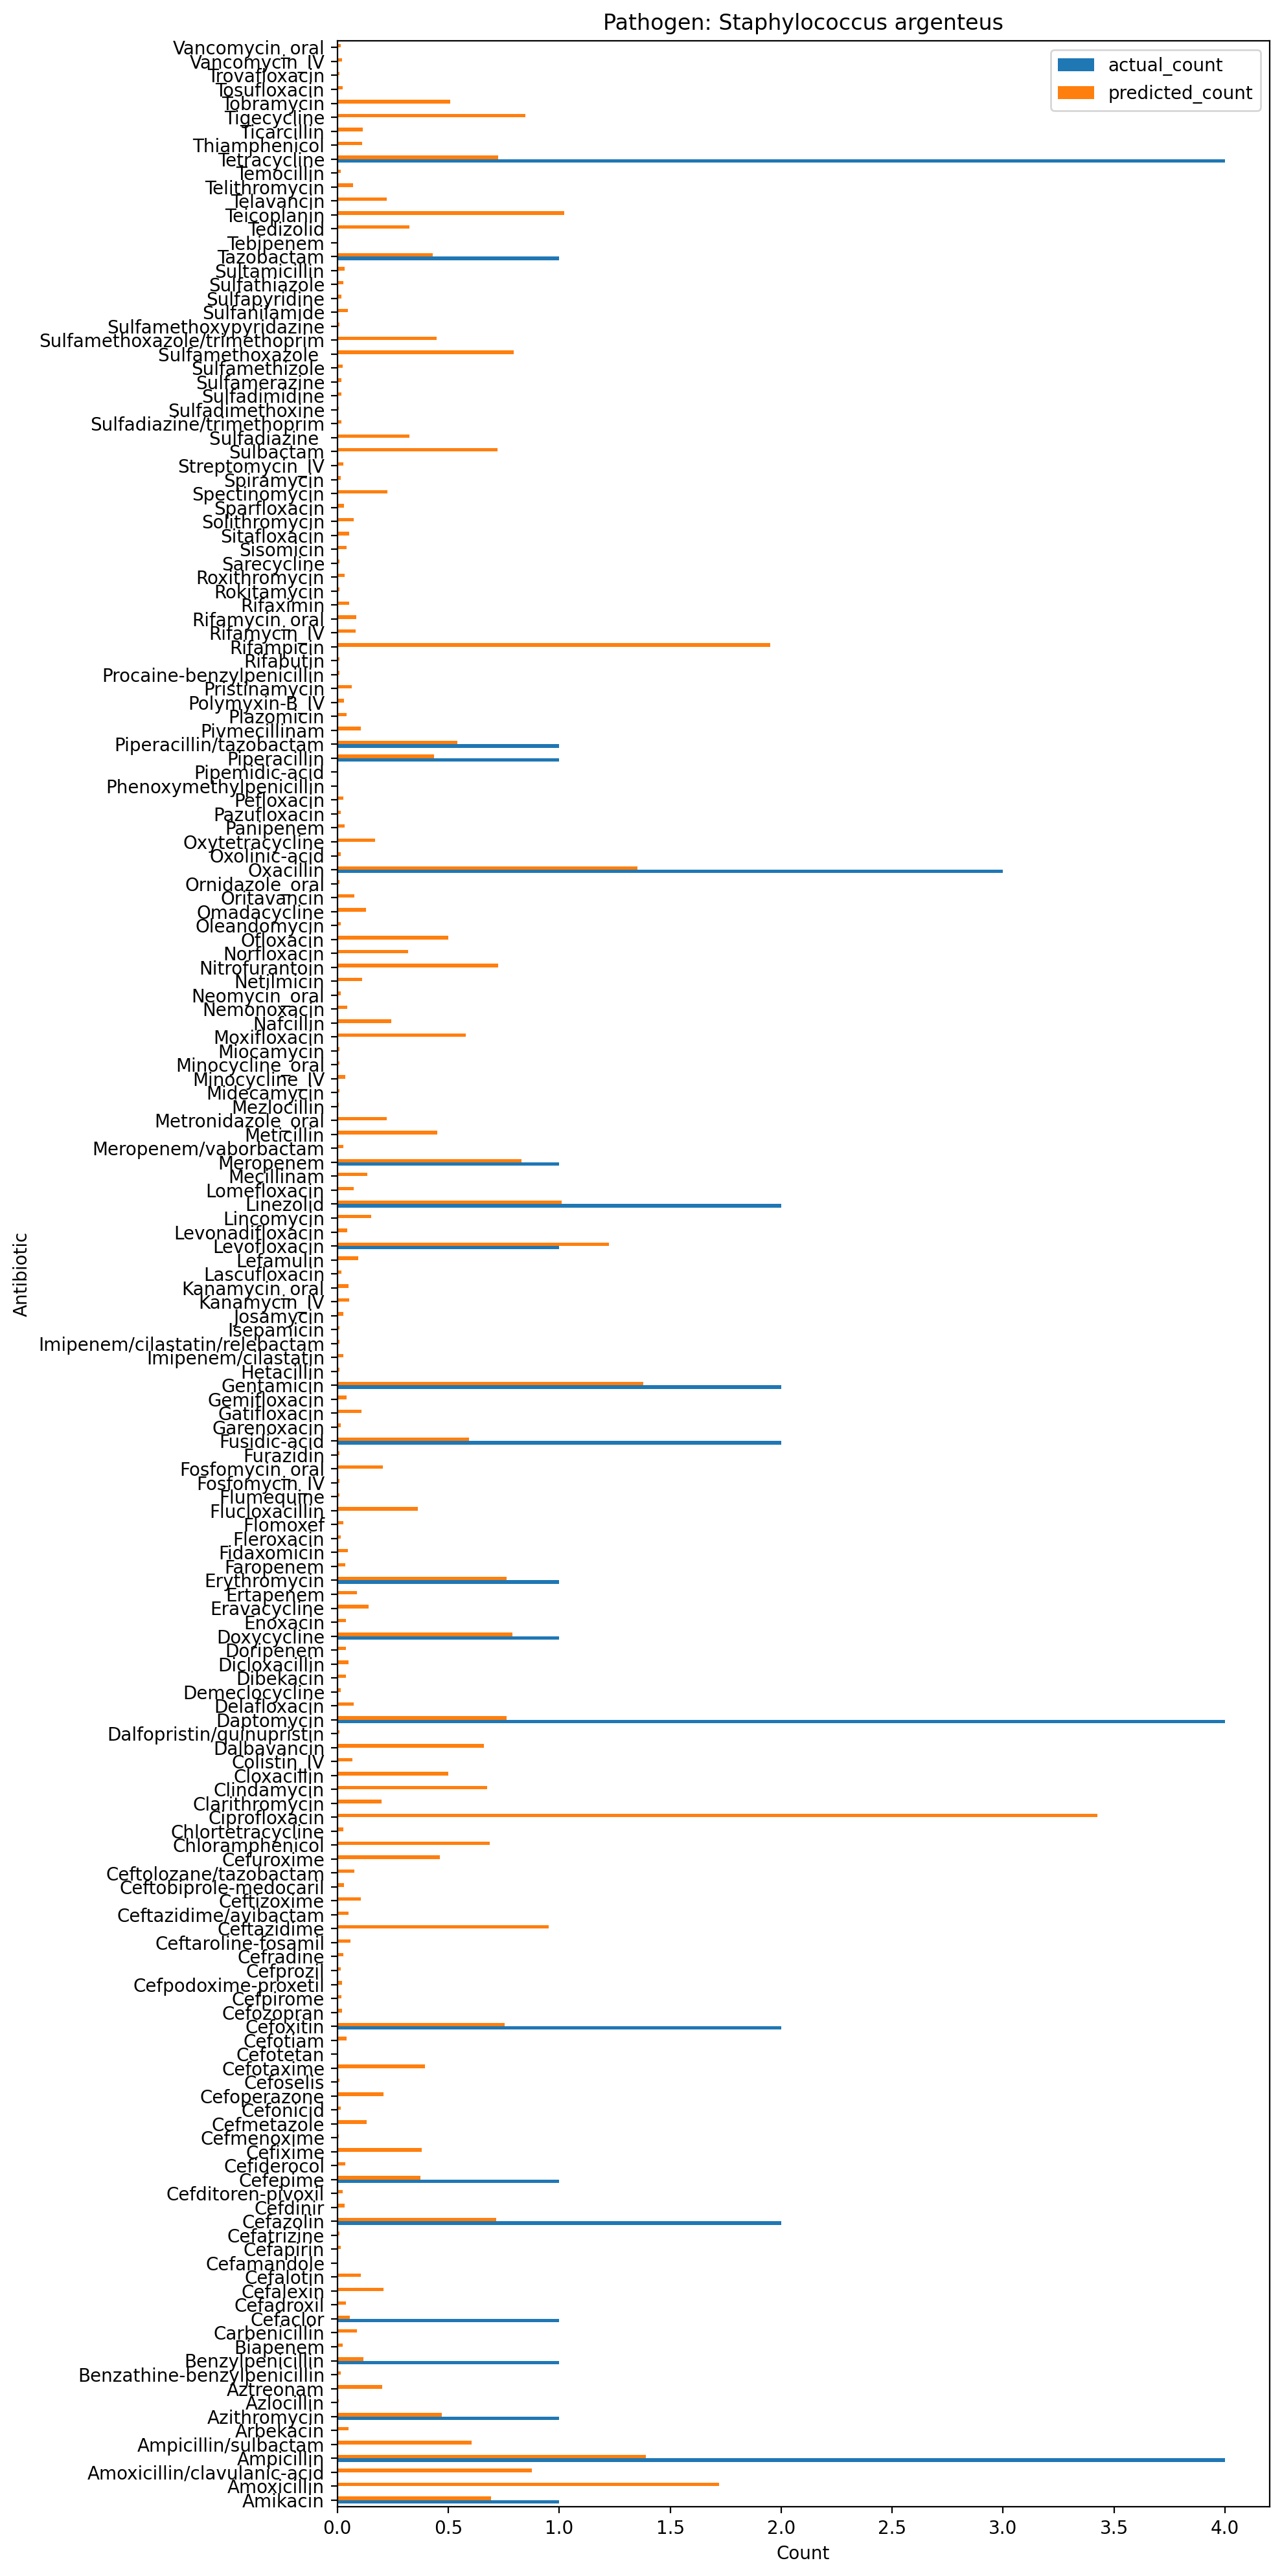

,pathogen,antibiotic,actual_count,predicted_count,difference
4032,Staphylococcus argenteus,Amikacin,1.0,0.692252,-0.307748
4033,Staphylococcus argenteus,Amoxicillin,0.0,1.718788,1.718788
4034,Staphylococcus argenteus,Amoxicillin/clavulanic-acid,0.0,0.876525,0.876525
4035,Staphylococcus argenteus,Ampicillin,4.0,1.389583,-2.610417
4036,Staphylococcus argenteus,Ampicillin/sulbactam,0.0,0.605560,0.605560
...,...,...,...,...,...
4279,Staphylococcus argenteus,Tosufloxacin,0.0,0.024135,0.024135
4280,Staphylococcus argenteus,Troleandomycin,0.0,0.000000,0.000000
4281,Staphylococcus argenteus,Trovafloxacin,0.0,0.009285,0.009285
4282,Staphylococcus argenteus,Vancomycin_IV,0.0,0.021691,0.021691


In [12]:
import random
import matplotlib.pyplot as plt

# pick one pathogen at random
pathogen = random.choice(list(set(results_df['pathogen'].astype(str))))

# filter rows for that pathogen
subset = results_df[results_df["pathogen"].str.contains(pathogen)].copy()

# drop antibiotics where both counts are 0 or NaN
subset = subset[~((subset["actual_count"].fillna(0) == 0) & 
                  (subset["predicted_count"].fillna(0) == 0))]

# plot if any data remains
if not subset.empty:
    subset.set_index("antibiotic")[["actual_count", "predicted_count"]].plot(
        kind="barh",
        figsize=(10, 20),
        title=f"Pathogen: {pathogen}"
    )
    plt.xlabel("Count")
    plt.ylabel("Antibiotic")
    plt.tight_layout()
    plt.show()
else:
    print(f"No non-empty counts found for pathogen {pathogen}")
results_df[results_df["pathogen"].str.contains(pathogen)]

---